# 04 · Final model: the best model with the best configuration

1. **Data** with the best configuration's preprocessing.
2. **Evidence**: the cross-validation results of notebooks 02 and 03 that led here (k = 5 by person, 3 seeds).
3. **Final training** on *all* persons for the median best epoch of the cross-validation folds (no held-out data is
   needed any more: the performance estimate comes from the cross-validation).
4. **Export**: `model.pt`, `config.json`, `norm_stats.json`, `model_card.md`.
5. **Inference** on preprocessed recordings: per rep the error, confidence, probabilities and α on the real frames,
   saved as `predictions.json` in the format the final product reads.
6. **Check on an unseen person** (`E_PANTS_MALE`, never used for training or model choice).

**How to run.** Run All after notebook 03 (a few minutes). **Outputs.** `results/04_final/`.

In [1]:
# ---- setup (every notebook starts with this cell) ----
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()     # research_folders/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output, Image
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
from squat_research.common import load_config, apply_overrides, results_dir, nice, read_json, write_json
from squat_research.dataset import build_dataset, load_dataset
from squat_research.engine import comparison_table, select_best, fold_scores, paired_test
from squat_research import viz, monitor
cfg = load_config()
print("research folder:", ROOT)
import yaml
from squat_research.engine import train_final, export, predict_recording
from squat_research.common import path
from squat_research.dataset import dataset_file
OUT = results_dir(cfg, "04_final"); FIG = results_dir(cfg, "04_final", "figures"); PRED = results_dir(cfg, "04_final", "predictions")
best_cfg = yaml.safe_load(open(results_dir(cfg, "03_ablation") / "best_config.yaml", encoding="utf-8"))
evidence = read_json(results_dir(cfg, "03_ablation") / "best_config.json")
best, epochs = best_cfg["final"]["model"], best_cfg["final"]["epochs"]
print(f"final model: {nice(best)}, configuration '{evidence['variant']}' {evidence['overrides'] or ''}, {epochs} epochs")

research folder: C:\Users\dynam\Desktop\Project1\research_folders
final model: CNN-LSTM, configuration 'full' , 15 epochs


## 1. Data

In [2]:
if not dataset_file(best_cfg).exists():
    build_dataset(best_cfg)
ds = load_dataset(best_cfg); C = ds["classes"]
print(f"{len(ds['y'])} reps, {len(set(ds['recording']))} recordings, {len(set(ds['person']))} persons, T = {ds['joints'].shape[1]}")

933 reps, 91 recordings, 18 persons, T = 64


## 2. Evidence (cross-validation, k = 5 by person, 3 seeds)

In [3]:
for step, f in (("notebook 02, model choice", results_dir(cfg, "02_model_comparison") / "summary.md"),
                ("notebook 03, best configuration", results_dir(cfg, "03_ablation") / "summary.md")):
    display(Markdown(f"**{step}.** " + f.read_text(encoding="utf-8")))
cmp = pd.read_csv(results_dir(cfg, "02_model_comparison") / "comparison.csv")
display(cmp[["name", "group", "macro_f1", "macro_f1_std", "rec_macro_f1", "alpha_drop"]])

**notebook 02, model choice.** **Chosen model: CNN-LSTM**: macro-F1 0.758 ± 0.108, recording level 0.777, α check 0.023 vs random 0.004, 155,398 parameters. Tied within one standard deviation: CNN-LSTM, 1D-CNN, TCN, BiGRU, BiLSTM, ST-Transformer. Best classical baseline: XGBoost (0.527).

**notebook 03, best configuration.** **Best configuration for CNN-LSTM: `full`** (the default settings): macro-F1 0.761 ± 0.106 (default 0.761). Final training length 15 epochs (median best epoch of the folds). Largest drops: side_camera_only (-0.261), world_axes (-0.175), train_persons_33pct (-0.144), angles_only (-0.140).

,name,group,macro_f1,macro_f1_std,rec_macro_f1,alpha_drop
0,CNN-LSTM,neural,0.758,0.108,0.777,0.023
1,1D-CNN,neural,0.747,0.089,0.763,0.054
2,TCN,neural,0.734,0.122,0.744,0.050
3,BiGRU,neural,0.717,0.100,0.754,0.031
4,BiLSTM,neural,0.693,0.078,0.737,0.007
5,ST-Transformer,neural,0.677,0.093,0.689,0.011
6,XGBoost,classical baseline,0.527,0.053,0.564,NaN
7,Random forest,classical baseline,0.508,0.052,0.517,NaN
8,Logistic regression,classical baseline,0.460,0.078,0.470,NaN


## 3. Final training on all persons

final CNN-LSTM: all 933 reps, 18 persons, 15 epochs on cuda
trained in 8 s, 155,398 parameters


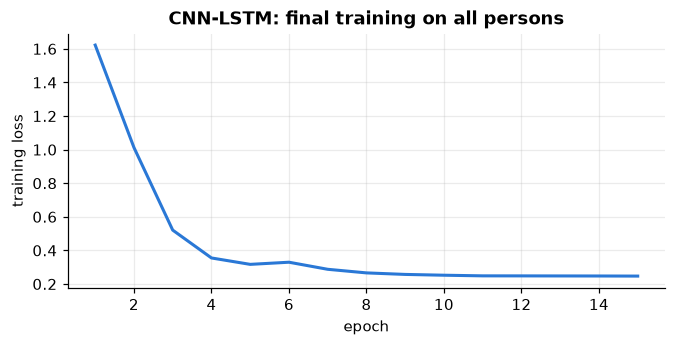

In [4]:
t0 = time.time()
r = train_final(best, ds, best_cfg, epochs)
print(f"trained in {time.time() - t0:.0f} s, {r['n_params']:,} parameters")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(r["history"]["train_loss"]) + 1), r["history"]["train_loss"], color=viz.ATTN, lw=2)
ax.set(xlabel="epoch", ylabel="training loss", title=f"{nice(best)}: final training on all persons")
viz.save(fig, FIG, "final_training_loss"); plt.show()

## 4. Export

In [5]:
cv_epochs = read_json(results_dir(cfg, "03_ablation") / "runs" / evidence["variant"] / best / "summary.json")["best_epochs"]
EXP = export(r, best, ds, best_cfg, OUT / "export", extra=dict(cv_macro_f1=evidence["macro_f1"], cv_macro_f1_std=evidence["macro_f1_std"],
                                                            configuration=evidence["variant"], overrides=evidence["overrides"],
                                                            epochs_trained=epochs, cv_best_epochs=cv_epochs))
print(f"trained for {epochs} epochs = median of the best epochs of the 15 cross-validation runs {cv_epochs}")
card = f"""# Squat error model: {nice(best)}

* Classes: {", ".join(C)}
* Data: {len(ds['y'])} reps, {len(set(ds['recording']))} recordings, {len(set(ds['person']))} persons (two-camera Pose2Sim, 29.97 fps)
* Configuration: `{evidence['variant']}` {evidence['overrides'] or '(defaults)'}; trained on all persons for {epochs} epochs
* Cross-validation (k = 5 by person, 3 seeds): macro-F1 {evidence['macro_f1']:.3f} ± {evidence['macro_f1_std']:.3f}, recording level {evidence['rec_macro_f1']:.3f}
* Parameters: {r['n_params']:,}
* Output per rep: class probabilities and alpha (64 frame-attention weights) -> alpha on the real frames for the 3D body
* Files: model.pt (weights), config.json (model, data and feature settings), norm_stats.json (z-score statistics)
* Limitations: 18 persons; the person is the main source of error; abnormal_tempo is not modelled.
"""
(EXP / "model_card.md").write_text(card, encoding="utf-8"); print(sorted(p.name for p in EXP.iterdir())); display(Markdown(card))

trained for 15 epochs = median of the best epochs of the 15 cross-validation runs [12, 15, 12, 20, 4, 20, 18, 13, 4, 21, 10, 3, 21, 16, 18]
['config.json', 'model.pt', 'model_card.md', 'norm_stats.json']


# Squat error model: CNN-LSTM

* Classes: correct, insufficient_depth, forward_lean, knee_valgus, knee_varus, heel_lift
* Data: 933 reps, 91 recordings, 18 persons (two-camera Pose2Sim, 29.97 fps)
* Configuration: `full` (defaults); trained on all persons for 15 epochs
* Cross-validation (k = 5 by person, 3 seeds): macro-F1 0.761 ± 0.106, recording level 0.790
* Parameters: 155,398
* Output per rep: class probabilities and alpha (64 frame-attention weights) -> alpha on the real frames for the 3D body
* Files: model.pt (weights), config.json (model, data and feature settings), norm_stats.json (z-score statistics)
* Limitations: 18 persons; the person is the main source of error; abnormal_tempo is not modelled.


## 5. Inference on a recording

`predict_recording(folder, export)` runs the whole chain on a preprocessed recording: features → normalisation → model →
per rep the error, confidence, probabilities and α; α is spread onto the real frames (10-frame windows, Gaussian
σ = 5 frames, peak 1) and multiplied by the confidence into an intensity timeline. These recordings were part of the
training data, so they show what the output looks like, not how accurate the model is.

p1 (person A, label correct): {'correct': 11}


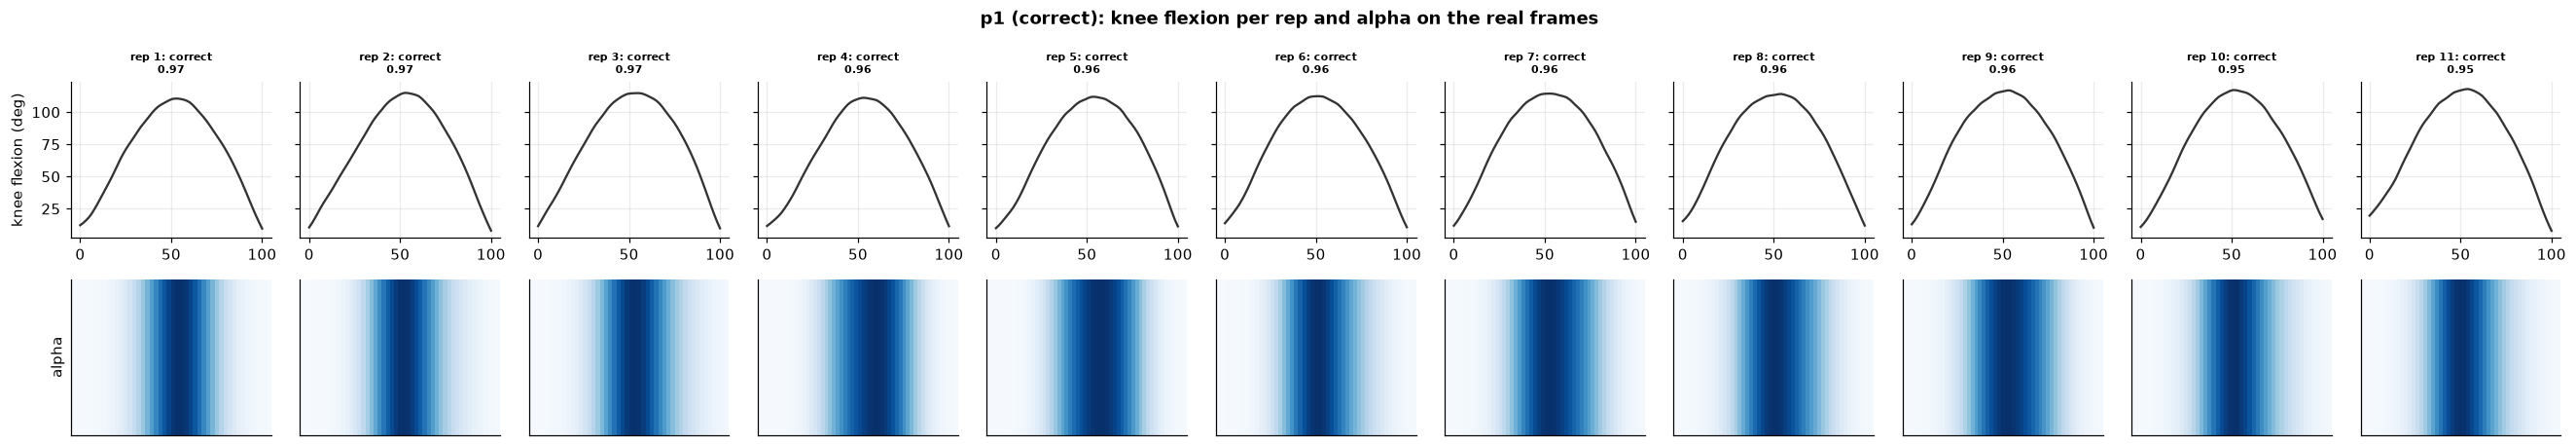

p2 (person A, label insufficient_depth): {'insufficient_depth': 11}


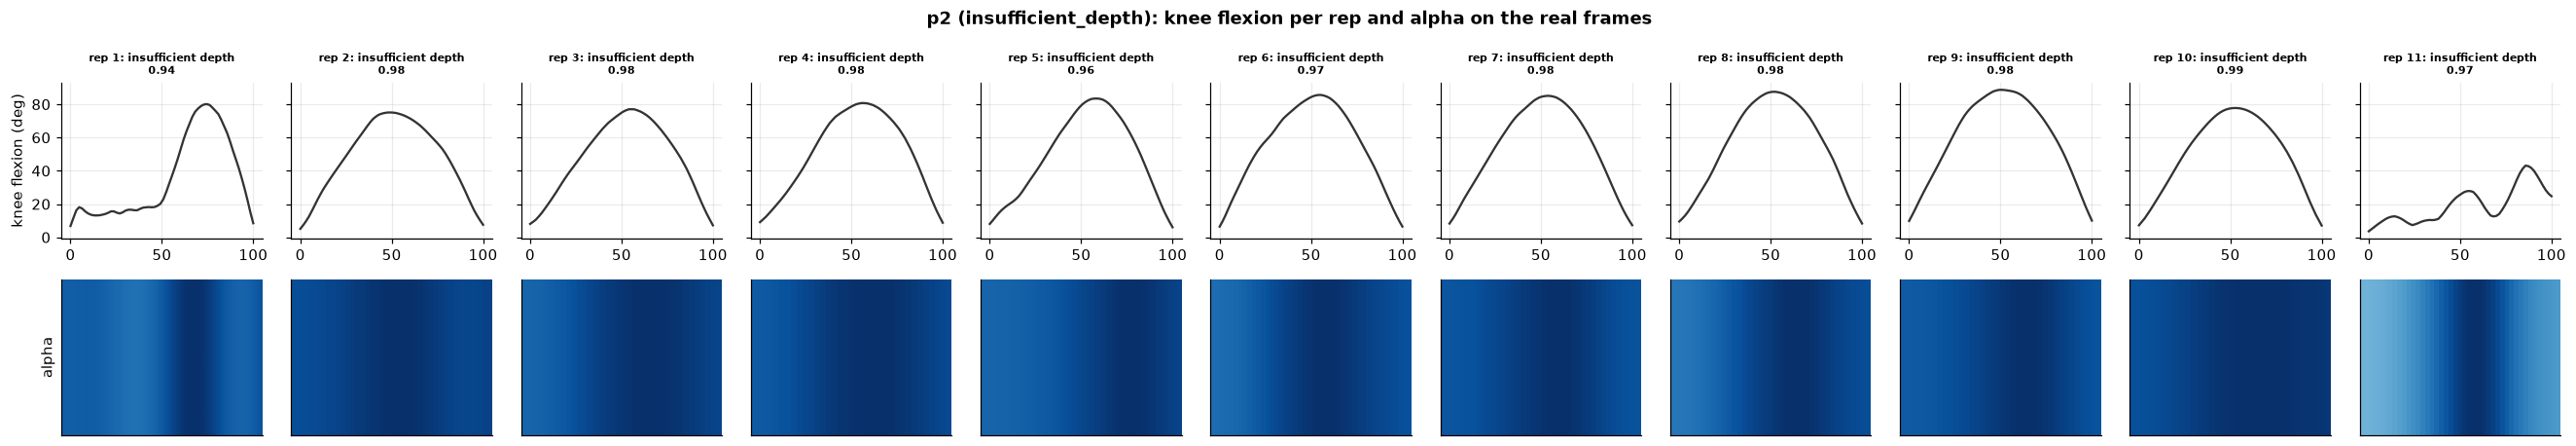

p3 (person A, label forward_lean): {'forward_lean': 10}


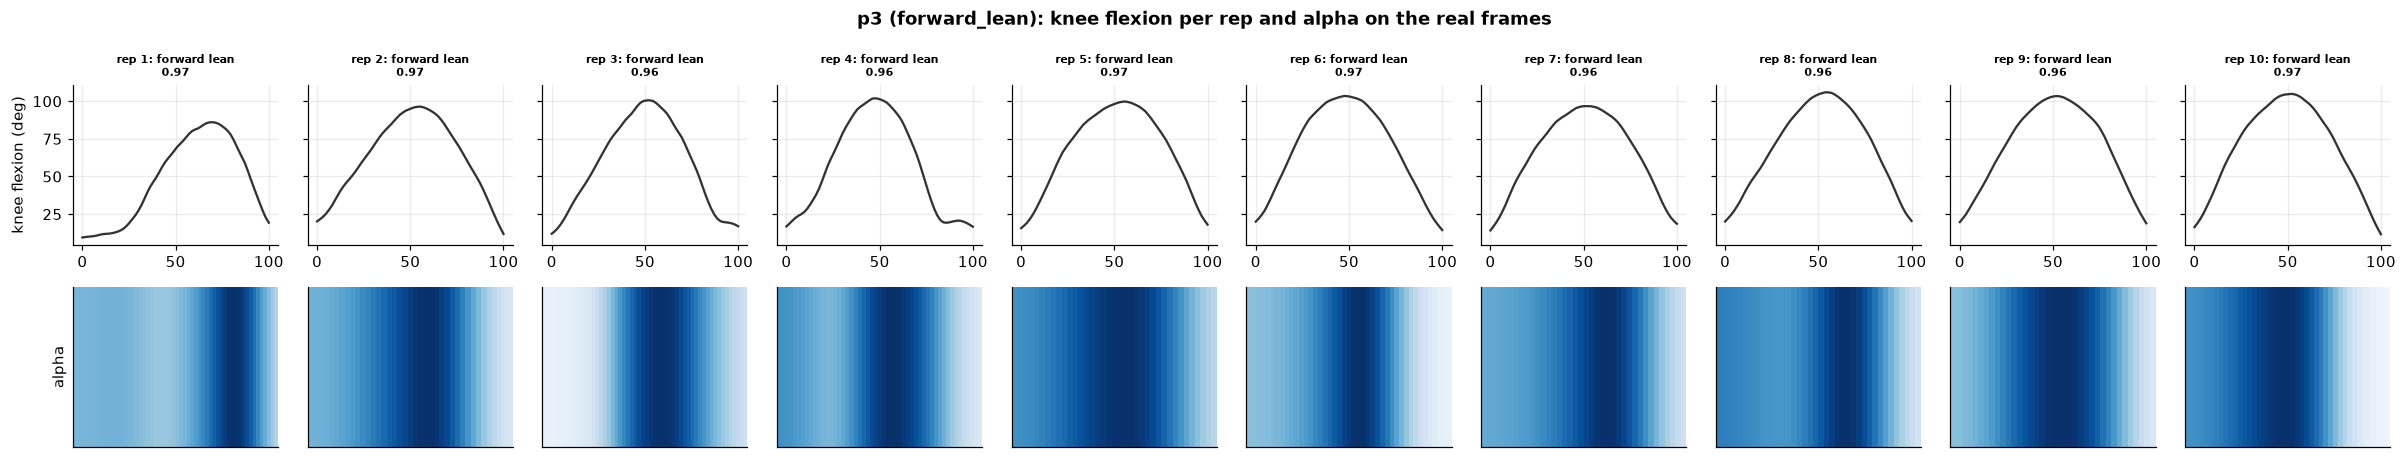

In [6]:
rec_root = path(best_cfg, "recordings")
man = pd.read_csv(path(best_cfg, "manifest"))
demo = man[man["include"]].groupby("label").head(1).head(3)
for row in demo.itertuples():
    p = predict_recording(rec_root / row.id, EXP)
    write_json(PRED / f"{row.id}.json", p)
    print(f"{row.id} (person {row.person}, label {row.label}):", pd.Series([x["label"] for x in p["reps"]]).value_counts().to_dict())
    n = len(p["reps"])
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 4.2), sharey="row", squeeze=False)
    for i, rep in enumerate(p["reps"]):
        axes[0, i].plot(np.linspace(0, 100, len(rep["flex"])), rep["flex"], color="#333")
        axes[0, i].set_title(f"rep {rep['rep']}: {rep['label'].replace('_', ' ')}\n{rep['confidence']:.2f}", fontsize=7)
        axes[1, i].imshow(np.array(rep["alpha_frames"])[None, :], aspect="auto", cmap="Blues", vmin=0, vmax=1)
        axes[1, i].set_yticks([]); axes[1, i].set_xticks([])
    axes[0, 0].set_ylabel("knee flexion (deg)"); axes[1, 0].set_ylabel("alpha")
    fig.suptitle(f"{row.id} ({row.label}): knee flexion per rep and alpha on the real frames", fontweight="bold")
    fig.tight_layout(); viz.save(fig, FIG, f"inference_{row.id}"); plt.show()

## 6. Check on a person the model has never seen (`E_PANTS_MALE`)

In [7]:
unseen = man[(man["person"] == "E_PANTS_MALE") & (man["label"].isin(C))]
rows = []
for row in unseen.itertuples():
    try:
        p = predict_recording(rec_root / row.id, EXP)
    except Exception as e:
        print(row.id, "skipped:", e); continue
    write_json(PRED / f"{row.id}.json", p)
    labels = [x["label"] for x in p["reps"]]
    vote = int(pd.DataFrame([x["probs"] for x in p["reps"]]).mean().idxmax()) if p["reps"] else None
    rows.append(dict(recording=row.id, true=row.label, reps=len(labels), rep_accuracy=np.mean([l == row.label for l in labels]) if labels else None,
                     recording_vote=C[vote] if vote is not None else None))
unseen_tab = pd.DataFrame(rows); unseen_tab.to_csv(OUT / "unseen_person_check.csv", index=False); display(unseen_tab)
if len(unseen_tab):
    print(f"rep accuracy on the unseen person: {unseen_tab['rep_accuracy'].mean():.2f}; recordings right: "
          f"{(unseen_tab['true'] == unseen_tab['recording_vote']).sum()}/{len(unseen_tab)} (left out of training for poor pose quality)")

,recording,true,reps,rep_accuracy,recording_vote
0,p22,correct,10,0.0,forward_lean
1,p24,insufficient_depth,10,0.0,forward_lean
2,p26,forward_lean,10,0.8,forward_lean
3,p28,knee_valgus,9,1.0,knee_valgus
4,p30,knee_varus,10,0.9,knee_varus
5,p32,heel_lift,10,1.0,heel_lift


rep accuracy on the unseen person: 0.62; recordings right: 4/6 (left out of training for poor pose quality)


## 7. Using the export

```python
from squat_research.engine import predict_recording
pred = predict_recording(r"<preprocessed recording folder>", r"research_folders/results/04_final/export")
```
`pred` has the fields of the final product's `predictions.json` (`classes`, `fps`, `n_frames`, per rep `label`, `confidence`,
`probs`, `alpha`, `alpha_frames`, and `intensity` over the whole timeline).